# Callout Line Plot Gallery

A callout line chart is a single line with the events that explain it written on the chart: each callout has a bold title, a line or two of text, and a leader pointing at the moment on the line it describes. It answers *what happened here?* without sending the reader to a footnote.

Callout line charts excel at:
- **Explaining a trend**: tie each peak, dip and level shift to the promotion, outage or launch behind it
- **Board and trading reviews**: one chart that carries the story on its own
- **Event calendars**: plot a promotions or incidents table straight onto the metric it affected

The callouts are placed automatically so that no text touches the line, another callout or a leader, and the y-axis is given extra headroom when the callouts need room.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openretailscience.plots import callout_line
from openretailscience.plots.styles.graph_utils import set_axis_shorthand

In [ ]:
# Hand-crafted demo datasets shared across the gallery examples. The events are built in and
# seeded week-to-week noise is added on top, so the callouts describe what the line really does.

rng = np.random.default_rng(7)

weeks = pd.date_range("2023-01-02", periods=104, freq="W-MON")
week_no = np.arange(104)
trend = 62_000 + week_no * 180.0
christmas = 34_000 * np.exp(-(((week_no % 52) - 50) ** 2) / 6)
easter = 9_000 * np.exp(-((week_no - 14) ** 2) / 1.5) + 10_000 * np.exp(-((week_no - 64) ** 2) / 1.5)
revenue = trend + christmas + easter + rng.normal(0, 2_200, 104)
revenue[36:39] -= [14_000, 19_000, 9_000]  # supplier strike, September 2023
revenue[78:] += 7_000  # loyalty relaunch, July 2024
weekly_revenue = pd.DataFrame({"week_start": weeks, "revenue": revenue.round(-2)})

launch = pd.DataFrame(
    {
        "weeks_since_launch": np.arange(-6, 13),
        "units": [398, 396, 423, 422, 398, 409, 1209, 977, 790, 698, 641, 587, 595, 854, 620, 589, 577, 558, 558],
    },
)
launch_events = pd.DataFrame(
    {
        "weeks_since_launch": [0, 7],
        "event": ["Launch week", "Week 7"],
        "what_happened": ["TV campaign and half-price introductory offer", "Second promotion, at a smaller discount"],
    },
)

## The Callouts Table

The callouts come from a second DataFrame, separate from the line's data, with one row per callout. This is the one the examples below use.

---

In [ ]:
events = pd.DataFrame(
    {
        "week_start": pd.to_datetime(["2023-04-10", "2023-09-18", "2023-12-18", "2024-07-01", "2024-12-16"]),
        "event": ["10 Apr 2023", "18 Sep 2023", "18 Dec 2023", "1 Jul 2024", "16 Dec 2024"],
        "what_happened": [
            "Easter week",
            "Supplier strike empties the chilled aisle for three weeks",
            "Christmas week peaks at $107K",
            "Loyalty scheme relaunch lifts the weekly baseline by about $8K",
            "A second Christmas record, $122K",
        ],
    },
)
events

,week_start,event,what_happened
0,2023-04-10,10 Apr 2023,Easter week
1,2023-09-18,18 Sep 2023,Supplier strike empties the chilled aisle for ...
2,2023-12-18,18 Dec 2023,Christmas week peaks at $107K
3,2024-07-01,1 Jul 2024,Loyalty scheme relaunch lifts the weekly basel...
4,2024-12-16,16 Dec 2024,"A second Christmas record, $122K"


What the table needs:

- **An x column** saying where on the line each callout points. It must be the same type as the line's x values: real dates (not strings) on a date axis, numbers on a numeric one. Each value must fall inside the line's x range, but it does not have to match a row: a value between two rows is placed on the line between them. Name it with `callout_x_col`, or leave that out when the column has the same name as `x_col`.
- **A title column, a text column, or both**, named with `callout_title_col` and `callout_text_col`. The title is drawn in bold exactly as given, the text goes under it, and long lines are wrapped. Every callout needs at least one of the two that is not blank.
- **No missing values** in those columns.

The column names are yours to choose, and any other columns are ignored, so an existing promotions calendar or incident log can be passed as it is.

## Events on a Revenue Line

Pass the line's data and the callouts table. The title is drawn as given, so format dates the way you want them read. The line is not aggregated, so pass one row per x value.

---

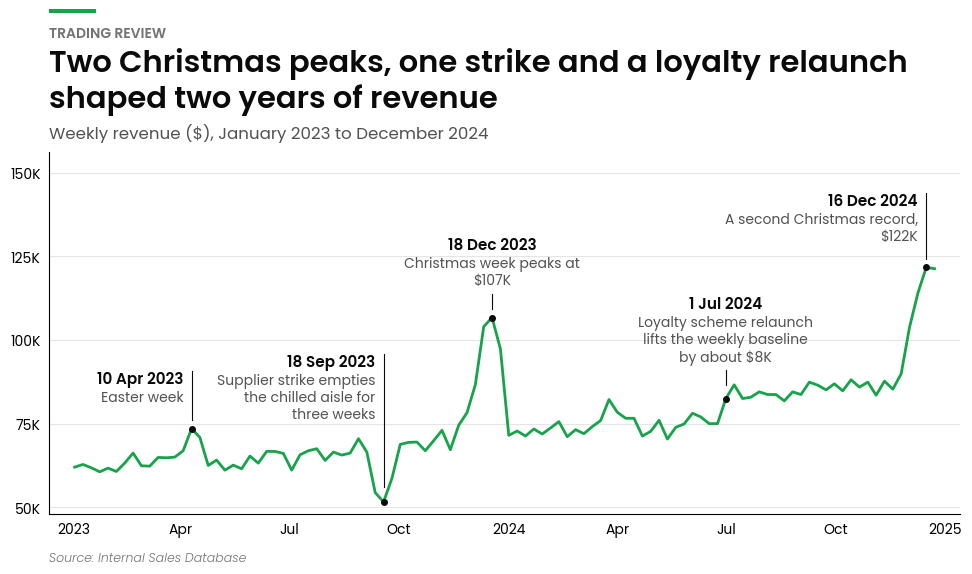

In [ ]:
ax = callout_line.plot(
    weekly_revenue,
    value_col="revenue",
    x_col="week_start",
    callouts=events,
    callout_title_col="event",
    callout_text_col="what_happened",
    eyebrow="Trading review",
    title="Two Christmas peaks, one strike and a loyalty relaunch shaped two years of revenue",
    subtitle="Weekly revenue ($), January 2023 to December 2024",
    source_text="Source: Internal Sales Database",
)
set_axis_shorthand(ax.yaxis)
plt.show()

## Text Only

Each callout can carry a bold title, wrapped text or both. Leave out `callout_title_col` when the description says enough and the x-axis already gives the date.

---

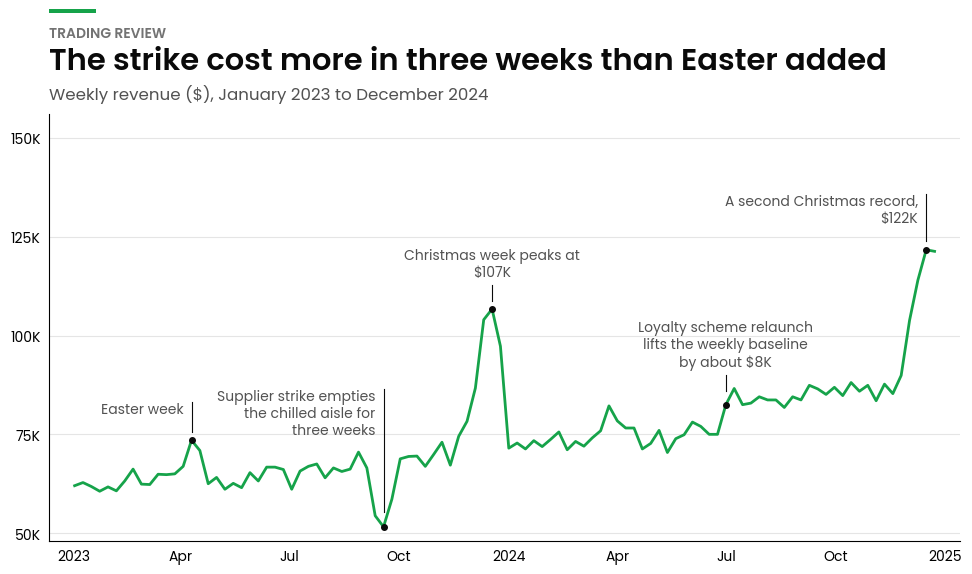

In [ ]:
ax = callout_line.plot(
    weekly_revenue,
    value_col="revenue",
    x_col="week_start",
    callouts=events,
    callout_text_col="what_happened",
    eyebrow="Trading review",
    title="The strike cost more in three weeks than Easter added",
    subtitle="Weekly revenue ($), January 2023 to December 2024",
)
set_axis_shorthand(ax.yaxis)
plt.show()

## Without Dots

By default a dot marks each callout's point on the line. Pass `show_markers=False` to leave the dots out; each leader then simply stops just short of the line. This suits a dense or noisy line, where dots add clutter.

---

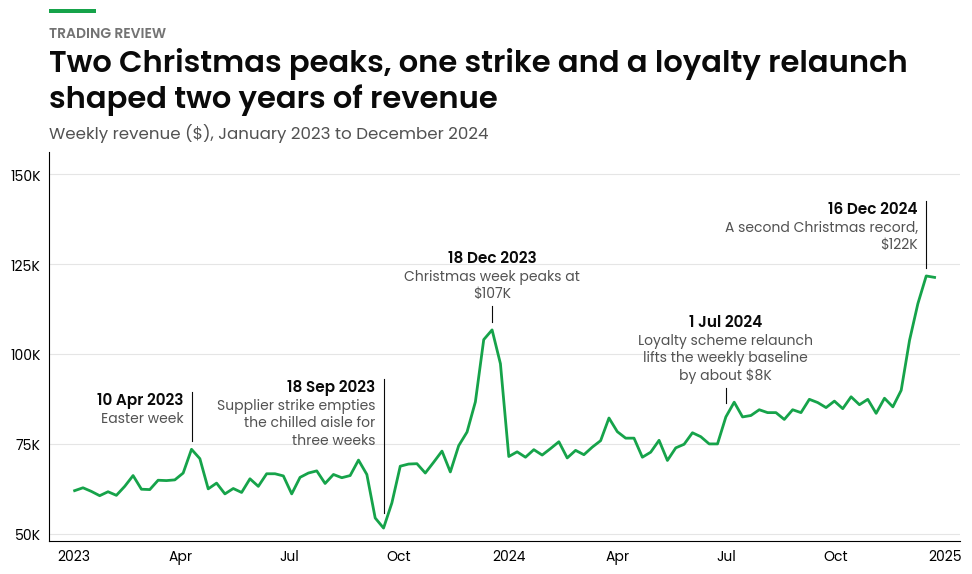

In [ ]:
ax = callout_line.plot(
    weekly_revenue,
    value_col="revenue",
    x_col="week_start",
    callouts=events,
    callout_title_col="event",
    callout_text_col="what_happened",
    show_markers=False,
    eyebrow="Trading review",
    title="Two Christmas peaks, one strike and a loyalty relaunch shaped two years of revenue",
    subtitle="Weekly revenue ($), January 2023 to December 2024",
)
set_axis_shorthand(ax.yaxis)
plt.show()

## A Numeric X-Axis

The x-axis can be numeric as well as dates, for sequences such as weeks since a launch. The callouts' x column must be the same type as the line's.

---

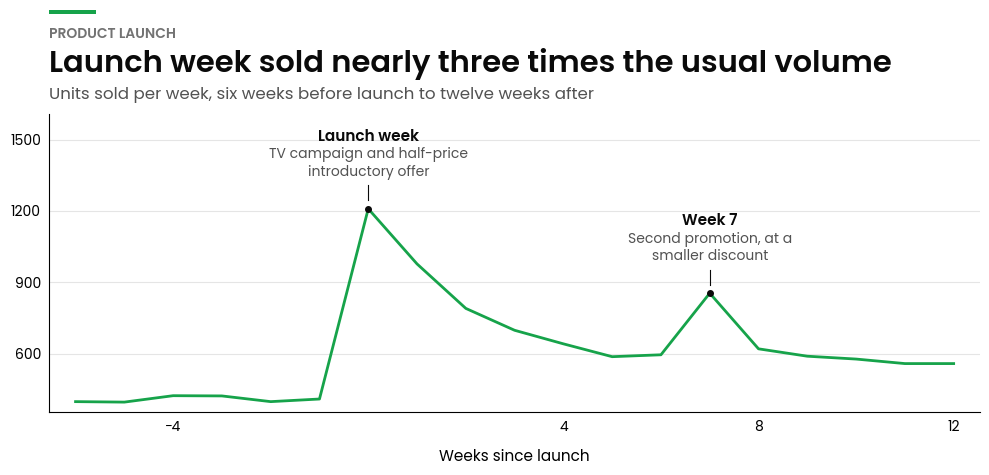

In [ ]:
ax = callout_line.plot(
    launch,
    value_col="units",
    x_col="weeks_since_launch",
    callouts=launch_events,
    callout_title_col="event",
    callout_text_col="what_happened",
    eyebrow="Product launch",
    title="Launch week sold nearly three times the usual volume",
    subtitle="Units sold per week, six weeks before launch to twelve weeks after",
    x_label="Weeks since launch",
    figsize=(10, 5),
)
plt.show()

## When Callouts Do Not Fit

The layout is worked out for the figure's size when you call `plot`, so set the size with `figsize` (or pass an `ax` on a figure already at its final size) and do not resize the figure or change the axis limits afterwards.

If the callouts cannot all be placed without overlapping, `plot` raises a `ValueError` that names the callouts left over. Use a larger `figsize`, shorter text, or fewer callouts. Several long callouts in consecutive weeks are the usual cause.